# Week 5 - Wed Lab (09/30/26) 

This code accompanies activities for the 09/30/26 lab.

**Table of Contents**

1. [Plicker Questions Code](#sec1)
2. [Cosine Similarity Whiteboard Activity - Your Task](#sec2)
3. [Wikipedia country-specific data](#sec3)

<a id="sec1"></a>
## 1. Plicker Questions Code

This code relates to the Question 13 on the Plicker set of questions for today. We will run the code line by line to see what is going on.

In [1]:
from datetime import datetime, timedelta

**Create a new datetime object**

In [2]:
date1 = datetime(2023, 5, 1)
type(date1)

datetime.datetime

**Create a new timedelta object**

In [3]:
delta = timedelta(days=10)
type(delta)

datetime.timedelta

In [4]:
print(delta)

10 days, 0:00:00


**Adding the two objects**

In [5]:
date2 = date1 + delta
print(date2)

2023-05-11 00:00:00


**Why is this possible?**

Let's show all methods / properties of the object:

In [6]:
dir(date1)

['__add__',
 '__class__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__ne__',
 '__new__',
 '__radd__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__rsub__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__sub__',
 '__subclasshook__',
 'astimezone',
 'combine',
 'ctime',
 'date',
 'day',
 'dst',
 'fold',
 'fromisocalendar',
 'fromisoformat',
 'fromordinal',
 'fromtimestamp',
 'hour',
 'isocalendar',
 'isoformat',
 'isoweekday',
 'max',
 'microsecond',
 'min',
 'minute',
 'month',
 'now',
 'replace',
 'resolution',
 'second',
 'strftime',
 'strptime',
 'time',
 'timestamp',
 'timetuple',
 'timetz',
 'today',
 'toordinal',
 'tzinfo',
 'tzname',
 'utcfromtimestamp',
 'utcnow',
 'utcoffset',
 'utctimetuple',
 'weekday',
 'year']

Let's look up the docstring of the method `__add__`, which is what is called when we use the + operator:

In [7]:
help(date1.__add__)

Help on method-wrapper:

__add__(value, /) unbound datetime.datetime method
    Return self+value.



**Conclusion:** There is a class method that will accept any value type and then act accordingly to figure out how to add that value to the date, if possible.

<a id="sec2"></a>
## 2. Cosine Similarity Whiteboard Activity

This activity was completed by hand, here is how to do it via Python code.

### Inputs for the problem

In [8]:
documents = [
    "Max likes Sam.",    # D1
    "Sam likes Max.",    # D2
    "Max and Sam.",      # D3
    "Winter likes fall." # D4
]

query = "Sam likes winter"

### Step 1: Create vocabulary of all terms

First I will concatenate all strings into one.

In [9]:
allText = " ".join(documents + [query])
print(allText)

Max likes Sam. Sam likes Max. Max and Sam. Winter likes fall. Sam likes winter


I don't want to have punctuation. There are several ways to do that. Let's see some:

#### Method 1: Iterate over the string, leave out punctuations

In [10]:
import string
print(string.punctuation)


!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [11]:
allText_noPunct = "".join([ch for ch in allText if not ch in string.punctuation])
print(allText_noPunct)

Max likes Sam Sam likes Max Max and Sam Winter likes fall Sam likes winter


### Method 2: Use built-in methods

Pythyn's built-in `str` class has many useful methods for translating a set of characters to another one. Let's see the method in action:

In [12]:
allText.translate(str.maketrans("", "", string.punctuation))

'Max likes Sam Sam likes Max Max and Sam Winter likes fall Sam likes winter'

What's going on?

In [13]:
print(str.maketrans("", "", string.punctuation))

{33: None, 34: None, 35: None, 36: None, 37: None, 38: None, 39: None, 40: None, 41: None, 42: None, 43: None, 44: None, 45: None, 46: None, 47: None, 58: None, 59: None, 60: None, 61: None, 62: None, 63: None, 64: None, 91: None, 92: None, 93: None, 94: None, 95: None, 96: None, 123: None, 124: None, 125: None, 126: None}


We can see that all ASCII Characters from 0-32 and from 65 to 90 are missing, because those characters will be deleted.

Here is what is happening:

```
str.maketrans(from_str, to_str, delete_chars)
#              ^          ^        ^
#           1st arg    2nd arg  3rd arg
```

* 1st argument (""): The characters you want to replace. (Empty string = replace nothing)

* 2nd argument (""): The characters to replace them with. (Empty string = no replacement mapping)

* 3rd argument (string.punctuation): The characters you want to delete entirely.

### Our vocabulary

Here is a Python one-liner that takes our variable `allText_noPunct` and find the unique words in it.

In [14]:
words = set(allText_noPunct.lower().split())
words

{'and', 'fall', 'likes', 'max', 'sam', 'winter'}

In [15]:
voc = sorted(words)
voc

['and', 'fall', 'likes', 'max', 'sam', 'winter']

### YOUR TURN

Write code to implement the other steps of the process shown in Slide 7.

**Show your process before writing any functions.**

**Use markdown to label the three remaining steps.**

### Step 2: Make a document-term matrix

Each word in the vocabulary gets a column. I go through each document, clean it, and count how many times each vocabulary word appears. I also make a vector for the query so I can compare them.

In [16]:
all_vectors = []
texts = documents + [query]

for text in texts:
    clean_text = "".join(ch for ch in text.lower() if ch not in string.punctuation)
    text_words = clean_text.split()
    counts = []
    for word in voc:
        counts.append(text_words.count(word))
    all_vectors.append(counts)

for name, vector in zip(["D1", "D2", "D3", "D4", "Query"], all_vectors):
    print(name, vector)

D1 [0, 0, 1, 1, 1, 0]
D2 [0, 0, 1, 1, 1, 0]
D3 [1, 0, 0, 1, 1, 0]
D4 [0, 1, 1, 0, 0, 1]
Query [0, 0, 1, 0, 1, 1]


I also put the same counts in a small table so I can check them against the whiteboard.

In [17]:
import pandas as pd

word_counts = pd.DataFrame(
    all_vectors,
    columns=voc,
    index=["D1", "D2", "D3", "D4", "Query"]
)

word_counts

,and,fall,likes,max,sam,winter
D1,0,0,1,1,1,0
D2,0,0,1,1,1,0
D3,1,0,0,1,1,0
D4,0,1,1,0,0,1
Query,0,0,1,0,1,1


### Step 3: Compare each document with the query

I calculated the dot product and the length of each vector so I could compare the documents to the query. D1 and D2 have the same values because they contain the same words, just in a different order.

In [18]:
import math

query_vector = all_vectors[-1]
query_length = math.sqrt(sum(number ** 2 for number in query_vector))

for i in range(4):
    doc_vector = all_vectors[i]
    dot_product = 0
    for j in range(len(voc)):
        dot_product += doc_vector[j] * query_vector[j]
    doc_length = math.sqrt(sum(number ** 2 for number in doc_vector))
    print("D" + str(i + 1), "dot product:", dot_product,
          "document length:", round(doc_length, 3),
          "query length:", round(query_length, 3))

D1 dot product: 2 document length: 1.732 query length: 1.732
D2 dot product: 2 document length: 1.732 query length: 1.732
D3 dot product: 1 document length: 1.732 query length: 1.732
D4 dot product: 2 document length: 1.732 query length: 1.732


### Step 4: Calculate cosine similarity

Cosine similarity is the dot product divided by both vector lengths. A higher number means the words overlap more, based on these word-count vectors.

In [19]:
scores = []
for i in range(4):
    doc_vector = all_vectors[i]
    dot_product = 0
    for j in range(len(voc)):
        dot_product += doc_vector[j] * query_vector[j]
    doc_length = math.sqrt(sum(number ** 2 for number in doc_vector))
    if doc_length == 0 or query_length == 0:
        similarity = 0
    else:
        similarity = dot_product / (doc_length * query_length)
    scores.append(similarity)
    print("D" + str(i + 1) + ":", round(similarity, 3))

D1: 0.667
D2: 0.667
D3: 0.333
D4: 0.667


**What I got:** D1 = 0.667, D2 = 0.667, D3 = 0.333, and D4 = 0.667. D1, D2, and D4 tie because they each share two of the three query words. D1 and D2 also have the exact same vector even though the words are in a different order.

This made it easier to see what cosine similarity is actually doing instead of just calling a function.

<a id="sec3"></a>
## 3. Wikipedia Country-Specific Data

If we know the URL of a date, for example:

```
https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv
```

we can use pandas to read the content of the file into a dataframe. 

In [20]:
import pandas as pd

url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

df = pd.read_csv(url, sep='\t')

df.head()

HTTPError: HTTP Error 403: Forbidden

Why did this happen? Wikimedia didn't like that we didn't identify ourselves. This is why we need to first get data with requests, then read it from pandas.

In [21]:
import pandas as pd
import requests, io

url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

headers = {'User-Agent': 'MyDataAnalysisScript/1.0 (contact: wendywellesley@gmail.com)'}
response = requests.get(url, headers=headers)

df = pd.read_csv(io.StringIO(response.text), sep='\t')
df.head()

,Algeria,DZ,ar.wikipedia,3947,Ø°ÙØ§Ø¡_Ø§ØµØ·ÙØ§Ø¹Ù,Q11660,122
0,Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
1,Argentina,AR,es.wikipedia,327209,JosÃ©_Mourinho,Q79983,114
2,Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
3,Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119
4,Argentina,AR,es.wikipedia,5640452,Michael_Jackson,Q2831,177


The dataframe doesn't have column name. 

**Your task:** Read the README file to find out the column names and add them to the dataframe.


### Column names and September pageviews

I added the column names first, then used the same one-day download idea for the September analysis.

In [22]:
import matplotlib.pyplot as plt
from pathlib import Path

output_folder = Path("week5_outputs")
output_folder.mkdir(exist_ok=True)
base_url = "https://analytics.wikimedia.org/published/datasets/country_project_page/"
column_names = ["country", "project", "page_id", "page_title", "item_id", "gbc"]


df = pd.read_csv(io.StringIO(response.text), sep="\t", names=column_names)
df.head()

,country,project,page_id,page_title,item_id,gbc
Algeria,DZ,ar.wikipedia,3947,Ø°ÙØ§Ø¡_Ø§ØµØ·ÙØ§Ø¹Ù,Q11660,122
Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
Argentina,AR,es.wikipedia,327209,JosÃ©_Mourinho,Q79983,114
Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119


I used MyDramaList to find recent Korean dramas from 2026 and picked 10 of the higher-rated ones. Then I searched the Wikipedia data for their article titles. Some titles were different from what I expected, so I had to try a few searches before finding matches for all 10 shows.

In [23]:

# Look for possible Wikipedia article titles
search_words = ["Four_Hands", "East_Palace", "Mousetrap"]

for word in search_words:
    matches = df[df["page_title"].str.contains(word, case=False, na=False)]
    print(word, ":", matches["page_title"].unique())


Four_Hands : ['Four_Hands,_Two_Sonatas']
East_Palace : ['The_East_Palace']
Mousetrap : ['Mousetrap_(TV_series)' 'The_Mousetrap']


In [24]:
search_words = [
    "Bona_Fide",
    "Sticky_Love",
    "Between_Steps",
    "My_Bias",
    "Ordinary_Jackpot"
]

for word in search_words:
    matches = df[df["page_title"].str.contains(word, case=False, na=False)]
    print(word, ":", matches["page_title"].unique())

Bona_Fide : ['A_Bona_Fide_Killer']
Sticky_Love : ['Our_Sticky_Love']
Between_Steps : []
My_Bias : ['My_Bias,_My_Boss']
Ordinary_Jackpot : ['The_Ordinary_Jackpot']


In [25]:
df[df["page_title"].str.contains("Between|Steps", case=False, na=False)]["page_title"].unique()

array(['The_Legend_of_Zelda:_A_Link_Between_Worlds',
       'List_of_The_Inbetweeners_episodes',
       'The_Fantastic_Four:_First_Steps', 'Mr_Inbetween',
       'The_Inbetweeners_(American_TV_series)', 'The_Inbetweeners',
       'The_39_Steps_(1935_film)', 'List_of_The_Inbetweeners_characters',
       'Between_the_World_and_Me',
       "My_Stepmother_and_Stepsisters_Aren't_Wicked",
       'The_Inbetweeners_2', 'Between_the_Buried_and_Me', 'Steps_(film)',
       'Boundaries_between_the_continents',
       'Between_Two_Ferns:_The_Movie', 'Sexual_practices_between_men',
       'Rocky_Steps', 'A_Thin_Line_Between_Love_and_Hate',
       'Between_Two_Ferns_with_Zach_Galifianakis',
       'The_Road_Between_Us:_The_Ultimate_Rescue',
       'Maxton_Hallâ\x80\x94The_World_Between_Us', 'Between_the_Lions',
       'Comparisons_between_Israel_and_Nazi_Germany',
       'Between_the_Buttons', 'Between_Scylla_and_Charybdis',
       'The_Ugly_Stepsister', 'Steps_(pop_group)',
       'Between_Two_Fires

In [26]:
search_words = ["Spooky", "Dive_into_You"]

for word in search_words:
    matches = df[df["page_title"].str.contains(word, case=False, na=False)]
    print(word, ":", matches["page_title"].unique())

Spooky : ['Spooky_Buddies' 'Spooky,_Scary_Skeletons' 'Spooky_Tooth'
 'Spooky_in_Love' 'Spooky_Little_Girl' 'Douglas_AC-47_Spooky'
 'Crayon_Shin-chan_the_Movie:_Spooky!_My_Yokai_Vacation']
Dive_into_You : ['Dive_into_You' 'Dive_Into_You']


I first tried using Between Steps, but I couldn't find a matching Wikipedia article in the September 29 data. I searched for a few other shows from MyDramaList and found Spooky in Love, so I used that instead. I also had to check the exact Wikipedia article titles because some were different from the names on MyDramaList.

In [27]:

# Show name, Wikipedia page title, MyDramaList rating


shows = [
    ("Four Hands, Two Sonatas", "Four_Hands,_Two_Sonatas", 8.7),
    ("A Shop for Killers Season 2", "A_Shop_for_Killers", 8.5),
    ("A Bona Fide Killer", "A_Bona_Fide_Killer", 8.4),
    ("The East Palace", "The_East_Palace", 8.4),
    ("Flex X Cop Season 2", "Flex_X_Cop", 8.2),
    ("Our Sticky Love", "Our_Sticky_Love", 8.2),
    ("Spooky in Love", "Spooky_in_Love", 8.0),
    ("My Bias, My Boss", "My_Bias,_My_Boss", 8.1),
    ("The Ordinary Jackpot", "The_Ordinary_Jackpot", 8.0),
    ("Mousetrap", "Mousetrap_(TV_series)", 8.0)
]

shows_df = pd.DataFrame(shows, columns=["show", "page_title", "mdl_rating"])
shows_df





,show,page_title,mdl_rating
0,"Four Hands, Two Sonatas","Four_Hands,_Two_Sonatas",8.7
1,A Shop for Killers Season 2,A_Shop_for_Killers,8.5
2,A Bona Fide Killer,A_Bona_Fide_Killer,8.4
3,The East Palace,The_East_Palace,8.4
4,Flex X Cop Season 2,Flex_X_Cop,8.2
5,Our Sticky Love,Our_Sticky_Love,8.2
6,Spooky in Love,Spooky_in_Love,8.0
7,"My Bias, My Boss","My_Bias,_My_Boss",8.1
8,The Ordinary Jackpot,The_Ordinary_Jackpot,8.0
9,Mousetrap,Mousetrap_(TV_series),8.0


### 3C. Start with one day

First I test the matching on the September 29 data that I already downloaded. This helps catch spelling mistakes before downloading the whole month.

In [28]:
wanted_titles = shows_df["page_title"].dropna().tolist()

one_day_matches = df[df["page_title"].isin(wanted_titles)].copy()
one_day_matches["date"] = "2026-09-29"
print("Matching rows:", len(one_day_matches))
print("Article titles found:", sorted(one_day_matches["page_title"].unique()))
one_day_matches.head()

Matching rows: 39
Article titles found: ['A_Bona_Fide_Killer', 'A_Shop_for_Killers', 'Flex_X_Cop', 'Four_Hands,_Two_Sonatas', 'Mousetrap_(TV_series)', 'My_Bias,_My_Boss', 'Our_Sticky_Love', 'Spooky_in_Love', 'The_East_Palace', 'The_Ordinary_Jackpot']


,country,project,page_id,page_title,item_id,gbc,date
Malaysia,MY,en.wikipedia,75697706,A_Shop_for_Killers,Q123999260,100,2026-09-29
Germany,DE,de.wikipedia,13931524,"Four_Hands,_Two_Sonatas",Q137271520,137,2026-09-29
Indonesia,ID,id.wikipedia,4750411,A_Bona_Fide_Killer,Q139411314,150,2026-09-29
India,IN,en.wikipedia,79116928,The_East_Palace,Q137723110,124,2026-09-29
India,IN,en.wikipedia,82034667,"Four_Hands,_Two_Sonatas",Q137271520,412,2026-09-29


### 3D. Collect every day in September 2026

I used a loop to go through all 30 days in September. For each day, I downloaded the data, found the Wikipedia pages for the shows I picked, and saved the matching rows. I also added the date so I could tell which day each row came from.

In [29]:
all_matches = []
failed_dates = []

for day in range(1, 31):
    day_string = "2026-09-" + str(day).zfill(2)
    day_url = base_url + day_string + ".tsv"

    try:
        result = requests.get(day_url, headers=headers, timeout=90)
        result.raise_for_status()
        daily_df = pd.read_csv(io.StringIO(result.text), sep="\t", names=column_names)
        matches = daily_df[daily_df["page_title"].isin(wanted_titles)].copy()
        matches["date"] = day_string
        all_matches.append(matches)
        print(day_string, "-", len(matches), "matching rows")
    except (requests.RequestException, pd.errors.ParserError) as error:
        print(day_string, "FAILED:", error)
        failed_dates.append(day_string)

if all_matches:
    september_views = pd.concat(all_matches, ignore_index=True)
else:
    september_views = pd.DataFrame(columns=column_names + ["date"])

print("Total matching rows:", len(september_views))
print("Failed dates:", failed_dates)

2026-09-01 - 93 matching rows
2026-09-02 - 79 matching rows
2026-09-03 - 74 matching rows
2026-09-04 - 73 matching rows
2026-09-05 - 91 matching rows
2026-09-06 - 88 matching rows
2026-09-07 - 80 matching rows
2026-09-08 - 70 matching rows
2026-09-09 - 66 matching rows
2026-09-10 - 68 matching rows
2026-09-11 - 65 matching rows
2026-09-12 - 84 matching rows
2026-09-13 - 84 matching rows
2026-09-14 - 69 matching rows
2026-09-15 - 66 matching rows
2026-09-16 - 59 matching rows
2026-09-17 - 56 matching rows
2026-09-18 - 48 matching rows
2026-09-19 - 62 matching rows
2026-09-20 - 67 matching rows
2026-09-21 - 48 matching rows
2026-09-22 - 48 matching rows
2026-09-23 - 44 matching rows
2026-09-24 - 39 matching rows
2026-09-25 - 40 matching rows
2026-09-26 - 47 matching rows
2026-09-27 - 51 matching rows
2026-09-28 - 42 matching rows
2026-09-29 - 39 matching rows
2026-09-30 - 32 matching rows
Total matching rows: 1872
Failed dates: []


### 3E. Save the CSV

This CSV keeps all matching rows rather than only the totals, because the assignment asks for the original country-level rows for the full month.

In [30]:
csv_path = output_folder / "september_2026_kdrama_pageviews.csv"
september_views.to_csv(csv_path, index=False)
print("Saved:", csv_path)
september_views.head()

Saved: week5_outputs/september_2026_kdrama_pageviews.csv


,country,project,page_id,page_title,item_id,gbc,date
0,MY,en.wikipedia,75697706,A_Shop_for_Killers,Q123999260,160,2026-09-01
1,DE,de.wikipedia,13931524,"Four_Hands,_Two_Sonatas",Q137271520,236,2026-09-01
2,ID,id.wikipedia,4750411,A_Bona_Fide_Killer,Q139411314,247,2026-09-01
3,IN,en.wikipedia,79116928,The_East_Palace,Q137723110,182,2026-09-01
4,IN,en.wikipedia,82034667,"Four_Hands,_Two_Sonatas",Q137271520,1082,2026-09-01


### 3F. Check how complete the results are

Before making claims about the full month, I want to see if I collected all 30 days and which pages were actually found.

In [31]:
found_titles = set(september_views["page_title"].unique())
not_found = sorted(set(wanted_titles) - found_titles)

print("Shows selected:", len(shows_df))
print("Shows with Wikipedia titles:", shows_df["page_title"].notna().sum())
print("Days loaded:", 30 - len(failed_dates), "/ 30")
print("Article titles not found in any downloaded rows:", not_found)
print("Countries found:", september_views["country"].nunique())

if failed_dates:
    print("WARNING: This is not a complete month. Fix failed dates before submitting full-month results.")
if not_found:
    print("Check those titles on Wikipedia; some might be wrong or have no qualifying data.")

Shows selected: 10
Shows with Wikipedia titles: 10
Days loaded: 30 / 30
Article titles not found in any downloaded rows: []
Countries found: 20


### 3G. Bar chart 1: Total pageviews by country

I add up the `gbc` values for each country across all selected articles and dates. The result is sorted from highest to lowest. If the same page appears in different language Wikipedias, both counts are included, just as in the classroom example.

Number of countries: 20
Top 10 countries:
country
US    119249
IN     95919
PH     65531
ID     51894
MY     41514
SG     30997
CA     16848
GB     14179
AU     10307
JP      7649
Name: gbc, dtype: int64


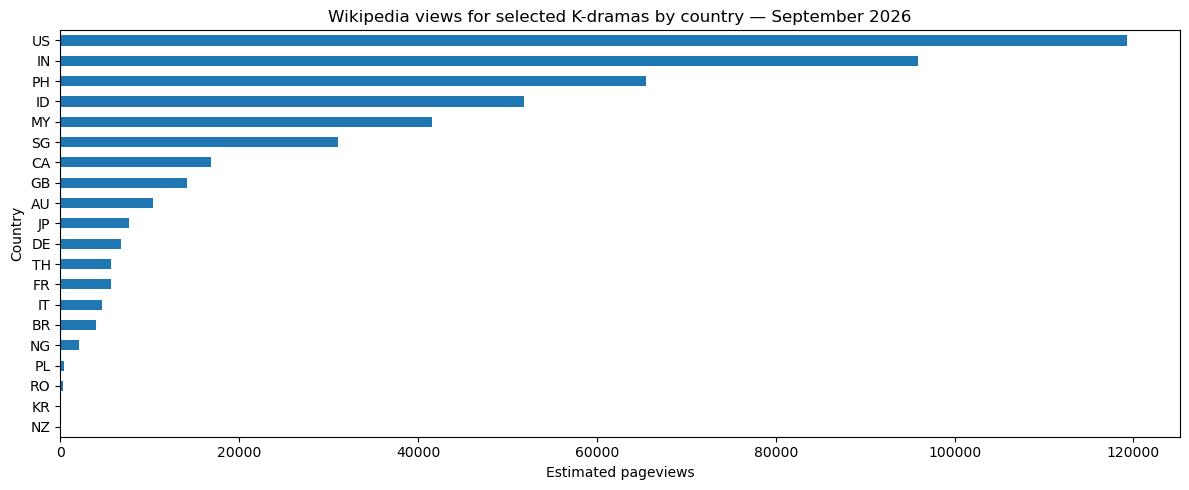

In [32]:
if september_views.empty:
    print("No matching rows to plot yet.")
else:
    country_totals = september_views.groupby("country")["gbc"].sum().sort_values(ascending=False)
    print("Number of countries:", len(country_totals))
    print("Top 10 countries:")
    print(country_totals.head(10))
    
    plt.figure(figsize=(12, max(5, len(country_totals) * 0.25)))
    country_totals.sort_values().plot(kind="barh")
    plt.title("Wikipedia views for selected K-dramas by country — September 2026")
    plt.xlabel("Estimated pageviews")
    plt.ylabel("Country")
    plt.tight_layout()
    plt.savefig(output_folder / "pageviews_by_country.png", dpi=150)
    plt.show()

### 3H. Bar chart 2: Total pageviews by show

Next I add up the counts for each Wikipedia article across all countries and days. This lets me see which selected drama articles were viewed the most.

page_title
Four_Hands,_Two_Sonatas    105309
Mousetrap_(TV_series)       85770
A_Bona_Fide_Killer          70404
Our_Sticky_Love             52686
My_Bias,_My_Boss            47183
The_Ordinary_Jackpot        41507
Spooky_in_Love              28820
Flex_X_Cop                  21950
A_Shop_for_Killers          18133
The_East_Palace             12167
Name: gbc, dtype: int64


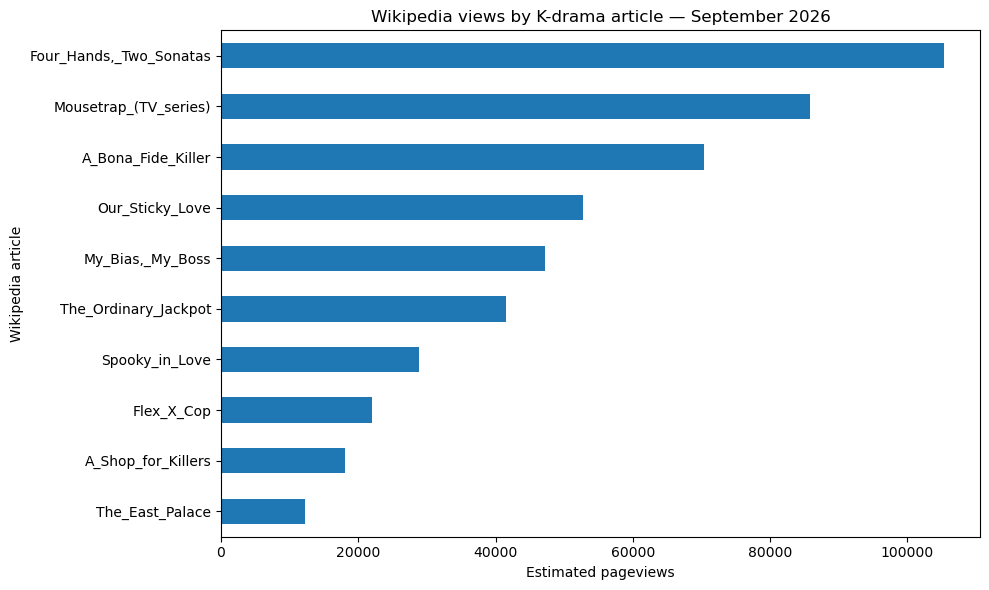

In [33]:
if september_views.empty:
    print("No matching rows to plot yet.")
else:
    show_totals = september_views.groupby("page_title")["gbc"].sum().sort_values(ascending=False)
    print(show_totals)
    
    plt.figure(figsize=(10, 6))
    show_totals.sort_values().plot(kind="barh")
    plt.title("Wikipedia views by K-drama article — September 2026")
    plt.xlabel("Estimated pageviews")
    plt.ylabel("Wikipedia article")
    plt.tight_layout()
    plt.savefig(output_folder / "pageviews_by_show.png", dpi=150)
    plt.show()

### 3I. Comparing Wikipedia views with MyDramaList ratings

Now I want to see whether the shows with higher ratings on MyDramaList also had more Wikipedia pageviews. I put the ratings and total views together so I could compare them.

In [34]:
if september_views.empty:
    print("Run the download cells first.")
else:
    totals_df = september_views.groupby("page_title", as_index=False)["gbc"].sum()
    comparison = shows_df.merge(totals_df, on="page_title", how="left")
    comparison = comparison.rename(columns={"gbc": "september_views"})
    comparison = comparison.sort_values("september_views", ascending=False)
    display(comparison)

,show,page_title,mdl_rating,september_views
0,"Four Hands, Two Sonatas","Four_Hands,_Two_Sonatas",8.7,105309
9,Mousetrap,Mousetrap_(TV_series),8.0,85770
2,A Bona Fide Killer,A_Bona_Fide_Killer,8.4,70404
5,Our Sticky Love,Our_Sticky_Love,8.2,52686
7,"My Bias, My Boss","My_Bias,_My_Boss",8.1,47183
8,The Ordinary Jackpot,The_Ordinary_Jackpot,8.0,41507
6,Spooky in Love,Spooky_in_Love,8.0,28820
4,Flex X Cop Season 2,Flex_X_Cop,8.2,21950
1,A Shop for Killers Season 2,A_Shop_for_Killers,8.5,18133
3,The East Palace,The_East_Palace,8.4,12167


Looking at the results, I don't think there's a clear relationship between MyDramaList ratings and Wikipedia pageviews. Four Hands, Two Sonatas had the highest rating (8.7) and also had the most Wikipedia views in September. But A Shop for Killers Season 2 had the second-highest rating (8.5), while its Wikipedia article was near the bottom in pageviews. One thing to keep in mind is that the Wikipedia page is for the whole series, not just Season 2. I think this shows that higher ratings don't always mean more Wikipedia views. People could also be searching for a show because they're curious about it, not necessarily because they've watched it or liked it.

**Limitations:** One limitation is that Wikipedia pageviews don't tell us how many people actually watched a drama. The dataset also doesn't include every single view, so some smaller numbers might be missing. I also used the Wikipedia pages for the overall series for A Shop for Killers Season 2 and Flex X Cop Season 2, which means those views aren't just for the second seasons.

**Dataset source:** https://analytics.wikimedia.org/published/datasets/country_project_page/00_README.html